In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")


In [2]:
rng = np.random.default_rng(42)
n_rows = 60_000

channels = np.array(["Search", "Social", "Email", "Display", "Affiliate"])
channel_lift = {
    "Search": 45_000,
    "Social": 30_000,
    "Email": 18_000,
    "Display": -8_000,
    "Affiliate": 24_000,
}

month_lift = {
    1: -8_000, 2: -5_000, 3: 0, 4: 3_000,
    5: 5_000, 6: 2_000, 7: -2_000, 8: 1_000,
    9: 6_000, 10: 9_000, 11: 14_000, 12: 18_000,
}

start_date = pd.Timestamp("2022-01-01")
end_date = pd.Timestamp("2025-12-31")
date_range_days = (end_date - start_date).days + 1

campaign_dates = start_date + pd.to_timedelta(
    rng.integers(0, date_range_days, size=n_rows),
    unit="D"
)
channel_values = rng.choice(channels, size=n_rows)

planned_budget = rng.integers(20_000, 1_000_001, size=n_rows)
planned_duration = rng.integers(7, 91, size=n_rows)
planned_audience = rng.integers(10_000, 1_000_001, size=n_rows)
offer_discount = np.round(rng.uniform(0, 40, size=n_rows), 2)

date_month = pd.DatetimeIndex(campaign_dates).month
date_year = pd.DatetimeIndex(campaign_dates).year

revenue = (
    1.35 * planned_budget
    + 0.24 * planned_audience
    + 900 * planned_duration
    + 2_600 * offer_discount
    + np.array([channel_lift[ch] for ch in channel_values])
    + np.array([month_lift[m] for m in date_month])
    + 14_000 * (date_year - 2022)
    + rng.normal(0, 12_000, size=n_rows)
)

raw_data = pd.DataFrame({
    "campaign_id": [f"CMP{i:06d}" for i in range(1, n_rows + 1)],
    "campaign_start_date": pd.DatetimeIndex(campaign_dates).strftime("%Y-%m-%d"),
    "channel": channel_values,
    "planned_budget_inr": planned_budget,
    "planned_duration_days": planned_duration,
    "planned_audience_size": planned_audience,
    "offer_discount_pct": offer_discount,
    "revenue_inr": np.maximum(0, np.round(revenue, 2)),
})

# Add a small amount of missingness to raw input fields.
for column in [
    "channel",
    "planned_budget_inr",
    "planned_duration_days",
    "planned_audience_size",
    "offer_discount_pct",
]:
    missing_rows = rng.choice(raw_data.index, size=int(n_rows * 0.001), replace=False)
    raw_data.loc[missing_rows, column] = np.nan

print("Rows and columns:", raw_data.shape)
raw_data.head()


Rows and columns: (60000, 8)


,campaign_id,campaign_start_date,channel,planned_budget_inr,planned_duration_days,planned_audience_size,offer_discount_pct,revenue_inr
0,CMP000001,2022-05-11,Search,21421.0,85.0,188668.0,6.93,219317.08
1,CMP000002,2025-02-04,Social,832030.0,87.0,301370.0,15.40,1379502.30
2,CMP000003,2024-08-14,Display,134467.0,17.0,199957.0,0.85,285135.59
3,CMP000004,2023-10-04,Email,738935.0,9.0,801749.0,34.30,1327940.02
4,CMP000005,2023-09-25,Search,36742.0,88.0,26242.0,26.68,264458.26


In [3]:
raw_data.to_csv("campaign_revenue_raw1.csv", index=False)
print("Saved raw dataset to campaign_revenue_raw.csv")


Saved raw dataset to campaign_revenue_raw.csv


In [5]:
df = pd.read_csv("campaign_revenue_raw1.csv")

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
df.head()


Dataset shape: (60000, 8)
Column names: ['campaign_id', 'campaign_start_date', 'channel', 'planned_budget_inr', 'planned_duration_days', 'planned_audience_size', 'offer_discount_pct', 'revenue_inr']


,campaign_id,campaign_start_date,channel,planned_budget_inr,planned_duration_days,planned_audience_size,offer_discount_pct,revenue_inr
0,CMP000001,2022-05-11,Search,21421.0,85.0,188668.0,6.93,219317.08
1,CMP000002,2025-02-04,Social,832030.0,87.0,301370.0,15.40,1379502.30
2,CMP000003,2024-08-14,Display,134467.0,17.0,199957.0,0.85,285135.59
3,CMP000004,2023-10-04,Email,738935.0,9.0,801749.0,34.30,1327940.02
4,CMP000005,2023-09-25,Search,36742.0,88.0,26242.0,26.68,264458.26


In [6]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   campaign_id            60000 non-null  object 
 1   campaign_start_date    60000 non-null  object 
 2   channel                59940 non-null  object 
 3   planned_budget_inr     59940 non-null  float64
 4   planned_duration_days  59940 non-null  float64
 5   planned_audience_size  59940 non-null  float64
 6   offer_discount_pct     59940 non-null  float64
 7   revenue_inr            60000 non-null  float64
dtypes: float64(5), object(3)
memory usage: 3.7+ MB


In [7]:
df.isna().sum().sort_values(ascending=False)


planned_budget_inr       60
channel                  60
planned_audience_size    60
planned_duration_days    60
offer_discount_pct       60
campaign_start_date       0
campaign_id               0
revenue_inr               0
dtype: int64

In [8]:
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Shape after duplicate removal:", df.shape)


Duplicate rows: 0
Shape after duplicate removal: (60000, 8)


In [9]:
df = df.dropna(subset=["revenue_inr"]).copy()

print("Shape after removing missing targets:", df.shape)


Shape after removing missing targets: (60000, 8)


In [10]:
df["campaign_start_date"] = pd.to_datetime(
    df["campaign_start_date"],
    errors="coerce"
)

print("Unparseable dates:", df["campaign_start_date"].isna().sum())

df = df.dropna(subset=["campaign_start_date"]).copy()

df["campaign_year"] = df["campaign_start_date"].dt.year
df["campaign_month"] = df["campaign_start_date"].dt.month.astype(str).str.zfill(2)

df[["campaign_start_date", "campaign_year", "campaign_month"]].head()


Unparseable dates: 0


,campaign_start_date,campaign_year,campaign_month
0,2022-05-11,2022,05
1,2025-02-04,2025,02
2,2024-08-14,2024,08
3,2023-10-04,2023,10
4,2023-09-25,2023,09


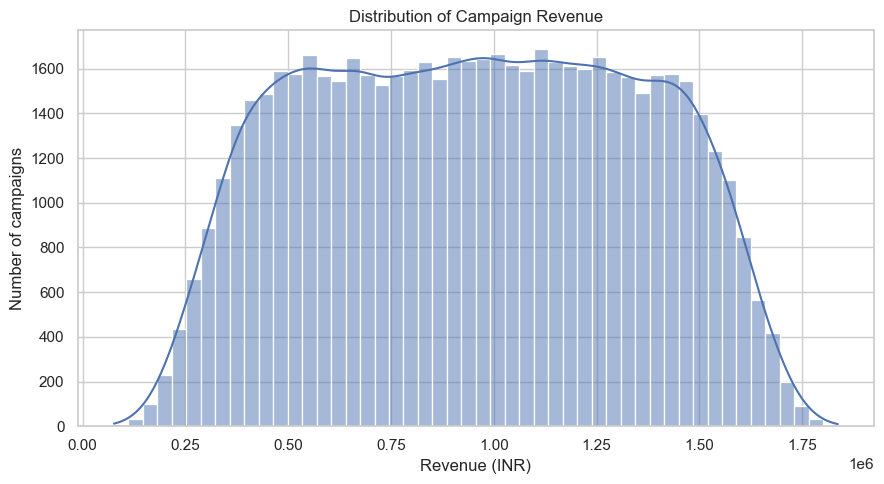

In [11]:
plt.figure(figsize=(9, 5))
sns.histplot(df["revenue_inr"], bins=50, kde=True)
plt.title("Distribution of Campaign Revenue")
plt.xlabel("Revenue (INR)")
plt.ylabel("Number of campaigns")
plt.tight_layout()
plt.show()


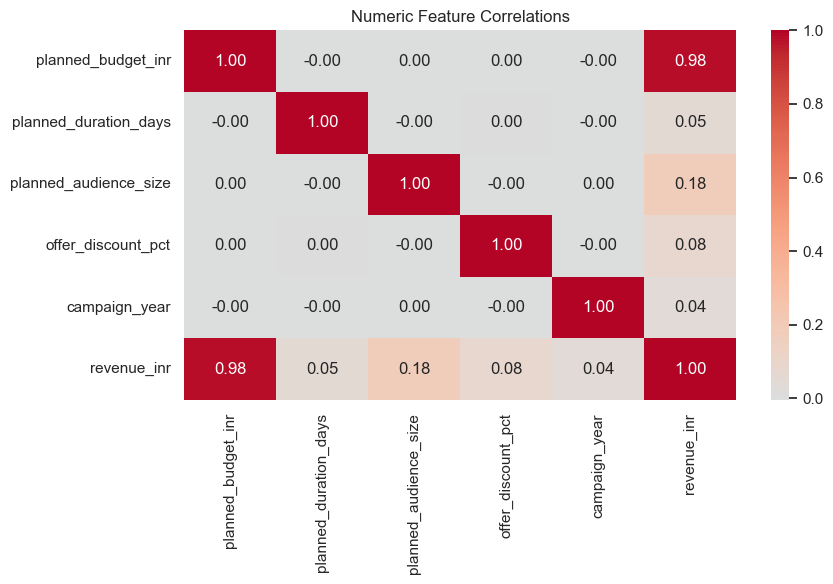

In [12]:
numeric_for_plot = [
    "planned_budget_inr",
    "planned_duration_days",
    "planned_audience_size",
    "offer_discount_pct",
    "campaign_year",
    "revenue_inr",
]

plt.figure(figsize=(9, 6))
sns.heatmap(
    df[numeric_for_plot].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Numeric Feature Correlations")
plt.tight_layout()
plt.show()


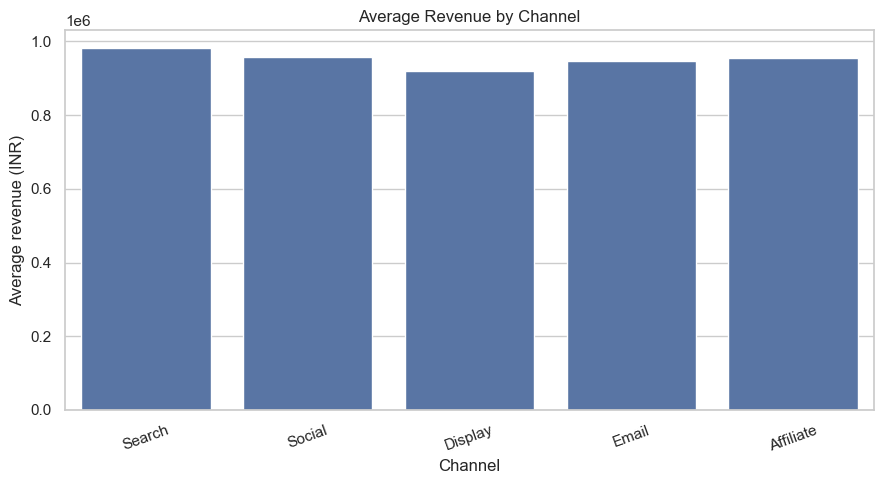

In [13]:
plt.figure(figsize=(9, 5))
sns.barplot(data=df, x="channel", y="revenue_inr", errorbar=None)
plt.title("Average Revenue by Channel")
plt.xlabel("Channel")
plt.ylabel("Average revenue (INR)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


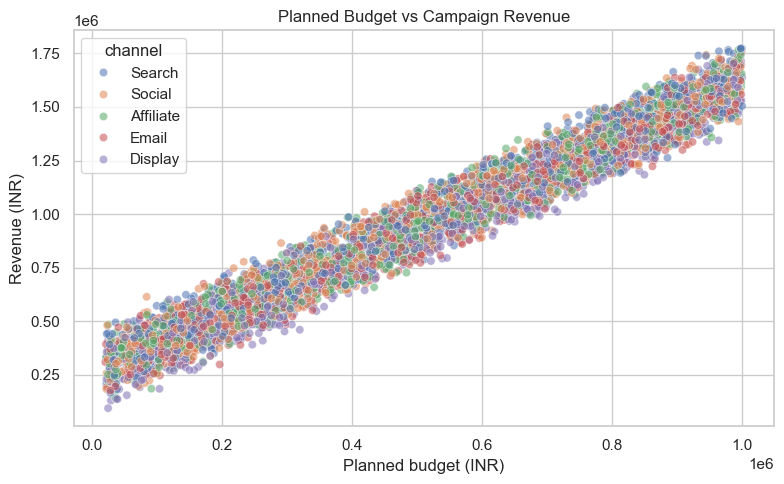

In [14]:
sample_for_plot = df.sample(
    n=min(5_000, len(df)),
    random_state=42
)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=sample_for_plot,
    x="planned_budget_inr",
    y="revenue_inr",
    hue="channel",
    alpha=0.55
)
plt.title("Planned Budget vs Campaign Revenue")
plt.xlabel("Planned budget (INR)")
plt.ylabel("Revenue (INR)")
plt.tight_layout()
plt.show()


In [15]:
X = df.drop(columns=[
    "campaign_id",
    "campaign_start_date",
    "revenue_inr",
])

y = df["revenue_inr"]

print("Predictor columns:", X.columns.tolist())
print("Target:", y.name)


Predictor columns: ['channel', 'planned_budget_inr', 'planned_duration_days', 'planned_audience_size', 'offer_discount_pct', 'campaign_year', 'campaign_month']
Target: revenue_inr


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))


Training rows: 48000
Test rows: 12000


In [17]:
numeric_columns = [
    "planned_budget_inr",
    "planned_duration_days",
    "planned_audience_size",
    "offer_discount_pct",
    "campaign_year",
]

categorical_columns = [
    "channel",
    "campaign_month",
]

print("Numeric columns:", numeric_columns)
print("Categorical columns:", categorical_columns)


Numeric columns: ['planned_budget_inr', 'planned_duration_days', 'planned_audience_size', 'offer_discount_pct', 'campaign_year']
Categorical columns: ['channel', 'campaign_month']


In [18]:
channel_mode = X_train["channel"].mode()[0]

X_train = X_train.copy()
X_test = X_test.copy()

X_train["channel"] = X_train["channel"].fillna(channel_mode)
X_test["channel"] = X_test["channel"].fillna(channel_mode)

print("Channel mode from training data:", channel_mode)
print("Missing channels in training data:", X_train["channel"].isna().sum())
print("Missing channels in test data:", X_test["channel"].isna().sum())


Channel mode from training data: Display
Missing channels in training data: 0
Missing channels in test data: 0


In [19]:
numeric_imputer = SimpleImputer(strategy="median")

X_train_numeric = pd.DataFrame(
    numeric_imputer.fit_transform(X_train[numeric_columns]),
    columns=numeric_columns,
    index=X_train.index
)

X_test_numeric = pd.DataFrame(
    numeric_imputer.transform(X_test[numeric_columns]),
    columns=numeric_columns,
    index=X_test.index
)

print("Remaining missing numeric values in training data:",
      X_train_numeric.isna().sum().sum())
print("Remaining missing numeric values in test data:",
      X_test_numeric.isna().sum().sum())


Remaining missing numeric values in training data: 0
Remaining missing numeric values in test data: 0


In [20]:
X_train_categorical = pd.get_dummies(
    X_train[categorical_columns],
    dtype=float
)

X_test_categorical = pd.get_dummies(
    X_test[categorical_columns],
    dtype=float
)

dummy_columns = X_train_categorical.columns.tolist()

X_test_categorical = X_test_categorical.reindex(
    columns=dummy_columns,
    fill_value=0
)

print("One-hot encoded columns:", dummy_columns)


One-hot encoded columns: ['channel_Affiliate', 'channel_Display', 'channel_Email', 'channel_Search', 'channel_Social', 'campaign_month_01', 'campaign_month_02', 'campaign_month_03', 'campaign_month_04', 'campaign_month_05', 'campaign_month_06', 'campaign_month_07', 'campaign_month_08', 'campaign_month_09', 'campaign_month_10', 'campaign_month_11', 'campaign_month_12']


In [21]:
X_train_final = pd.concat(
    [X_train_numeric, X_train_categorical],
    axis=1
)

X_test_final = pd.concat(
    [X_test_numeric, X_test_categorical],
    axis=1
)

print("Training matrix shape:", X_train_final.shape)
print("Test matrix shape:", X_test_final.shape)
print("Same feature columns:", X_train_final.columns.equals(X_test_final.columns))


Training matrix shape: (48000, 22)
Test matrix shape: (12000, 22)
Same feature columns: True


In [22]:
model = LinearRegression()
model.fit(X_train_final, y_train)

print("Model training complete.")


Model training complete.


In [23]:
y_pred = model.predict(X_test_final)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Test R²:   {r2:.4f}")
print(f"Test MAE:  ₹{mae:,.2f}")
print(f"Test RMSE: ₹{rmse:,.2f}")


Test R²:   0.9981
Test MAE:  ₹9,844.07
Test RMSE: ₹16,902.66


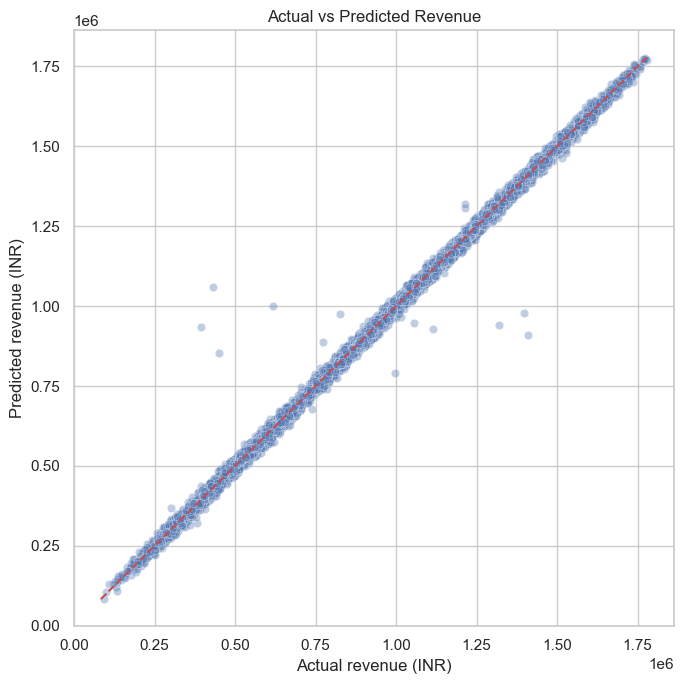

In [24]:
plt.figure(figsize=(7, 7))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.35)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], "r--")

plt.title("Actual vs Predicted Revenue")
plt.xlabel("Actual revenue (INR)")
plt.ylabel("Predicted revenue (INR)")
plt.tight_layout()
plt.show()


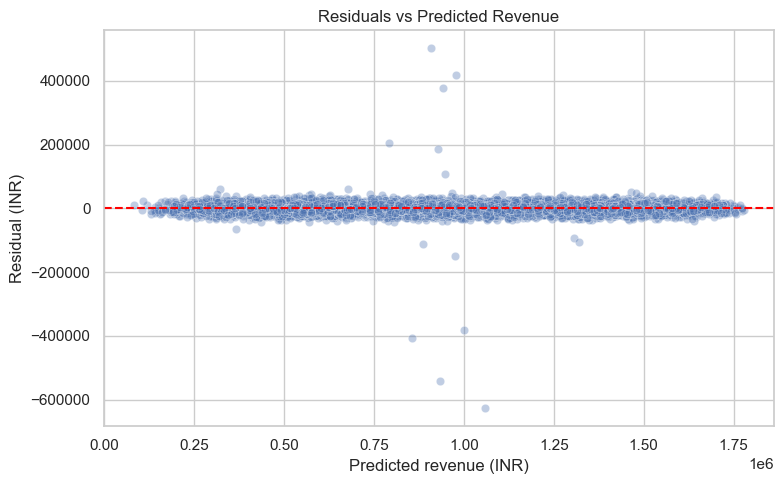

In [25]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.35)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuals vs Predicted Revenue")
plt.xlabel("Predicted revenue (INR)")
plt.ylabel("Residual (INR)")
plt.tight_layout()
plt.show()


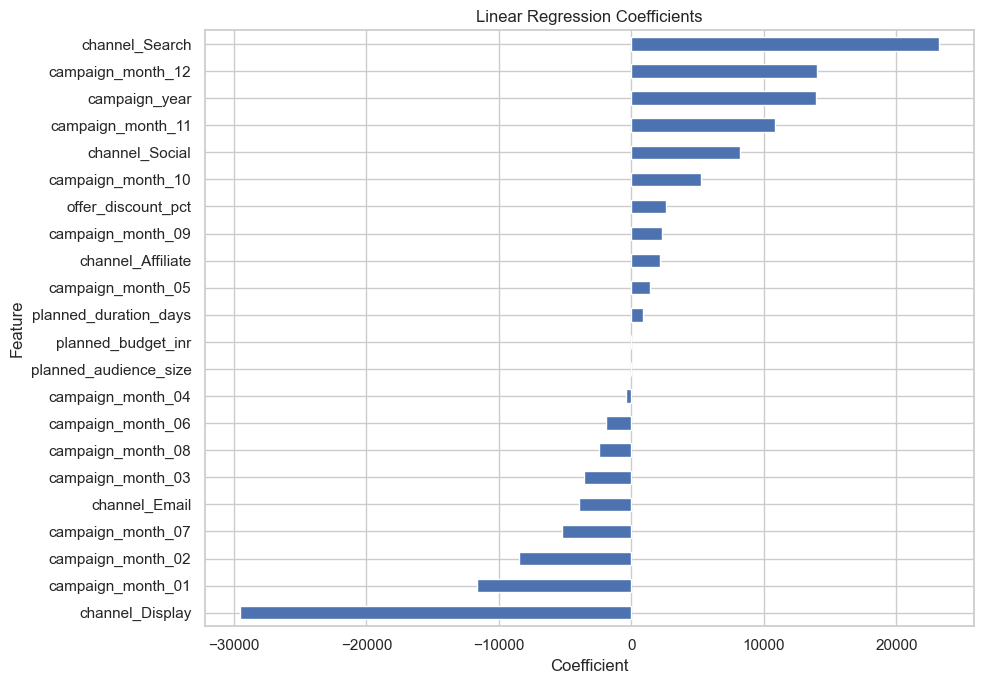

In [26]:
coefficients = pd.Series(
    model.coef_,
    index=X_train_final.columns
).sort_values()

plt.figure(figsize=(10, 7))
coefficients.plot(kind="barh")
plt.title("Linear Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [27]:
model_artifact = {
    "model": model,
    "numeric_imputer": numeric_imputer,
    "numeric_columns": numeric_columns,
    "categorical_columns": categorical_columns,
    "dummy_columns": dummy_columns,
    "channel_mode": channel_mode,
}

joblib.dump(model_artifact, "campaign_revenue_model.joblib")
print("Saved model and preprocessing details to campaign_revenue_model.joblib")


Saved model and preprocessing details to campaign_revenue_model.joblib


In [28]:
loaded_artifact = joblib.load("campaign_revenue_model.joblib")

loaded_model = loaded_artifact["model"]
loaded_imputer = loaded_artifact["numeric_imputer"]

print("Loaded model artifact.")


Loaded model artifact.


In [29]:
new_campaign = pd.DataFrame([{
    "campaign_id": "CMP_NEW_001",
    "campaign_start_date": "2026-01-15",
    "channel": "Search",
    "planned_budget_inr": 250_000,
    "planned_duration_days": 30,
    "planned_audience_size": 150_000,
    "offer_discount_pct": 10,
}])

new_campaign["campaign_start_date"] = pd.to_datetime(
    new_campaign["campaign_start_date"],
    errors="coerce"
)

new_campaign["campaign_year"] = new_campaign["campaign_start_date"].dt.year
new_campaign["campaign_month"] = (
    new_campaign["campaign_start_date"].dt.month.astype(str).str.zfill(2)
)

new_campaign["channel"] = new_campaign["channel"].fillna(
    loaded_artifact["channel_mode"]
)

new_numeric = pd.DataFrame(
    loaded_imputer.transform(new_campaign[loaded_artifact["numeric_columns"]]),
    columns=loaded_artifact["numeric_columns"],
    index=new_campaign.index
)

new_categorical = pd.get_dummies(
    new_campaign[loaded_artifact["categorical_columns"]],
    dtype=float
)

new_categorical = new_categorical.reindex(
    columns=loaded_artifact["dummy_columns"],
    fill_value=0
)

new_features = pd.concat([new_numeric, new_categorical], axis=1)
predicted_revenue = loaded_model.predict(new_features)[0]

print(f"Predicted campaign revenue: ₹{predicted_revenue:,.2f}")


Predicted campaign revenue: ₹519,186.15


In [30]:

import pandas as pd

# 1. Create new campaign inputs
new_campaign = pd.DataFrame([
    {
        "campaign_id": "CMP_001",
        "campaign_start_date": "2026-01-15",
        "channel": "Search",
        "planned_budget_inr": 250000,
        "planned_duration_days": 30,
        "planned_audience_size": 150000,
        "offer_discount_pct": 10
    },
    {
        "campaign_id": "CMP_002",
        "campaign_start_date": "2026-03-10",
        "channel": "Social",
        "planned_budget_inr": 500000,
        "planned_duration_days": 45,
        "planned_audience_size": 300000,
        "offer_discount_pct": 20
    },
    {
        "campaign_id": "CMP_003",
        "campaign_start_date": "2026-06-20",
        "channel": "Email",
        "planned_budget_inr": 100000,
        "planned_duration_days": 15,
        "planned_audience_size": 50000,
        "offer_discount_pct": 5
    },
    {
        "campaign_id": "CMP_004",
        "campaign_start_date": "2026-09-05",
        "channel": "Display",
        "planned_budget_inr": 750000,
        "planned_duration_days": 60,
        "planned_audience_size": 500000,
        "offer_discount_pct": 25
    },
    {
        "campaign_id": "CMP_005",
        "campaign_start_date": "2026-11-15",
        "channel": "Affiliate",
        "planned_budget_inr": 200000,
        "planned_duration_days": 25,
        "planned_audience_size": 100000,
        "offer_discount_pct": 8
    }
])


# 2. Convert campaign date
new_campaign["campaign_start_date"] = pd.to_datetime(
    new_campaign["campaign_start_date"],
    errors="coerce"
)


# 3. Extract date features
new_campaign["campaign_year"] = (
    new_campaign["campaign_start_date"].dt.year
)

new_campaign["campaign_month"] = (
    new_campaign["campaign_start_date"]
    .dt.month.astype(str).str.zfill(2)
)


# 4. Handle missing channel values
new_campaign["channel"] = new_campaign["channel"].fillna(
    loaded_artifact["channel_mode"]
)


# 5. Process numerical features
new_numeric = pd.DataFrame(
    loaded_imputer.transform(
        new_campaign[loaded_artifact["numeric_columns"]]
    ),
    columns=loaded_artifact["numeric_columns"],
    index=new_campaign.index
)


# 6. Process categorical features
new_categorical = pd.get_dummies(
    new_campaign[loaded_artifact["categorical_columns"]],
    dtype=float
)


# 7. Match training dummy columns
new_categorical = new_categorical.reindex(
    columns=loaded_artifact["dummy_columns"],
    fill_value=0
)


# 8. Combine numerical and categorical features
new_features = pd.concat(
    [new_numeric, new_categorical],
    axis=1
)


# 9. Predict revenue
predicted_revenue = loaded_model.predict(new_features)


# 10. Display predictions
results = pd.DataFrame({
    "campaign_id": new_campaign["campaign_id"],
    "channel": new_campaign["channel"],
    "planned_budget_inr": new_campaign["planned_budget_inr"],
    "predicted_revenue": predicted_revenue
})

results["predicted_revenue"] = results["predicted_revenue"].round(2)

print("CAMPAIGN REVENUE PREDICTIONS")
display(results)


CAMPAIGN REVENUE PREDICTIONS


,campaign_id,channel,planned_budget_inr,predicted_revenue
0,CMP_001,Search,250000,519186.15
1,CMP_002,Social,500000,925368.60
2,CMP_003,Email,100000,248660.14
3,CMP_004,Display,750000,1305574.29
4,CMP_005,Affiliate,200000,431364.41
